# NutriTerra — disponibilité alimentaire et pertes

**Simulation pédagogique : données synthétiques.**

Les sources couvrent 180 territoires, 18 produits et quinze années. Les flux sont exprimés en tonnes, les facteurs énergétiques en kcal/kg et la population en personnes. Des valeurs d’importations manquent et certains bilans sont incomplets. Les décideurs veulent savoir dans quelle mesure ces défauts modifient les comparaisons.

## Objectif et démarche

Proposer un panel de territoires à étudier, documenter la qualité des bilans et chiffrer des scénarios théoriques sans assimiler disponibilité nationale et consommation individuelle.

- Les unités, périodes et identifiants permettent-ils une jointure sans duplication ? Quels pays-années ont un bilan complet ?
- Quelle disponibilité calorique pondérée observe-t-on et comment diffère-t-elle d’une moyenne simple des pays ?
- Quels produits contribuent le plus à l’énergie disponible et aux pertes ? Les territoires les moins disponibles dépendent-ils davantage des importations ?
- Combien de kcal théoriques une réduction des pertes de 10, 25 ou 50 % rendrait-elle disponibles ? Comment les conclusions varient-elles selon trois références caloriques illustratives ?
- Quels territoires restent prioritaires lorsque l’on change les hypothèses et que l’on exclut les valeurs imputées ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_faux': '1=faux simulé, 0=authentique simulé', 'diagonale': 'mm', 'hauteur_gauche': 'mm', 'hauteur_droite': 'mm', 'marge_haute': 'mm', 'marge_basse': 'mm', 'longueur': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — défaut = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pièces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [6]:
nc, ny, npd = (180, 15, 18)

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
pop = pd.MultiIndex.from_product([np.arange(nc), np.arange(2010, 2025)], names=['pays_id', 'annee']).to_frame(index=False)
pop['population'] = np.round(RNG.uniform(400000.0, 95000000.0, nc)[pop.pays_id] * (1 + RNG.uniform(0.002, 0.025, nc)[pop.pays_id]) ** (pop.annee - 2010)).astype(int)

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
prod = pd.DataFrame({'produit_id': np.arange(npd), 'categorie': np.repeat(['Cereales', 'Legumineuses', 'Viandes', 'Fruits', 'Legumes', 'Autres'], 3), 'kcal_kg': RNG.uniform(400, 3600, npd).round(1)})

## Étape 7 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [9]:
d = pd.MultiIndex.from_product([np.arange(nc), np.arange(2010, 2025), np.arange(npd)], names=['pays_id', 'annee', 'produit_id']).to_frame(index=False).merge(pop, on=['pays_id', 'annee'], validate='many_to_one').merge(prod, on='produit_id', validate='many_to_one')

## Étape 8 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [10]:
kgpc = RNG.uniform(7, 28, npd)[d.produit_id] * RNG.lognormal(0, 0.18, len(d))
d['production_t'] = kgpc * d.population / 1000
d['importations_t'] = d.production_t * RNG.uniform(0.02, 0.4, len(d))
d['exportations_t'] = d.production_t * RNG.uniform(0.01, 0.22, len(d))
d['variation_stock_t'] = d.production_t * RNG.uniform(-0.03, 0.03, len(d))
d['pertes_t'] = d.production_t * RNG.uniform(0.02, 0.12, len(d))
d['alimentation_animale_t'] = d.production_t * RNG.uniform(0.03, 0.18, len(d))
d['autres_usages_t'] = d.production_t * 0.03

## Étape 9 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [11]:
d = d.drop(columns=['population', 'categorie', 'kcal_kg'])
d.loc[RNG.choice(len(d), 380, replace=False), 'importations_t'] = np.nan
d.loc[:24, 'production_t'] = -1
d = pd.concat([d, d.iloc[500:600]], ignore_index=True)

## Étape 10 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [12]:
source(pop, 'population', 'pays-année', {'population': 'personnes'})
source(prod, 'produits', 'produit', {'kcal_kg': 'kcal/kg'})
source(d, 'bilans', 'pays-année-produit', {c: 'tonnes/an' for c in d if c.endswith('_t')})

## Étape 11 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [13]:
v = clean(d, ['pays_id', 'annee', 'produit_id'], lambda x: x.production_t.ge(0) & x.pays_id.isin(pop.pays_id) & x.produit_id.isin(prod.produit_id), 'bilans')
v = v.sort_values(['pays_id', 'produit_id', 'annee'])
v['importations_imputees'] = v.importations_t.isna()
v['importations_t'] = v.groupby(['pays_id', 'produit_id']).importations_t.transform(lambda x: x.interpolate(limit_direction='both'))
assert v.importations_t.notna().all()

## Étape 12 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [14]:
v = v.merge(pop, on=['pays_id', 'annee'], validate='many_to_one').merge(prod, on='produit_id', validate='many_to_one')
v['disponibilite_t'] = v.production_t + v.importations_t - v.exportations_t + v.variation_stock_t - v.pertes_t - v.alimentation_animale_t - v.autres_usages_t
assert v.disponibilite_t.ge(0).all()

## Étape 13 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [15]:
v['kcal_jour_personne'] = v.disponibilite_t * 1000 * v.kcal_kg / v.population / 365.25
v['gain_reduction_pertes_25'] = v.pertes_t * 0.25 * 1000 * v.kcal_kg / v.population / 365.25
csv(v, CLEAN / 'bilans_enrichis.csv')

## Étape 14 — Contrôler et rapprocher les tables

Les clés et les règles de validité protègent le grain des données. Les exclusions sont tracées et les jointures sont contrôlées avant les calculs.

In [16]:
c = v.groupby(['pays_id', 'annee']).agg(kcal_jour_personne=('kcal_jour_personne', 'sum'), population=('population', 'first'), gain_scenario=('gain_reduction_pertes_25', 'sum'), production_t=('production_t', 'sum'), imports_t=('importations_t', 'sum'), produits_observes=('produit_id', 'nunique')).reset_index()
c = pop[['pays_id', 'annee']].merge(c, on=['pays_id', 'annee'], how='left', validate='one_to_one')
c['population'] = c.population.fillna(pop.population)
c['produits_observes'] = c.produits_observes.fillna(0).astype(int)
c['bilan_complet'] = c.produits_observes.eq(npd)
c['dependance_imports'] = c.imports_t / (c.production_t + c.imports_t)

## Étape 15 — Calculer les indicateurs

Les agrégations conservent les dimensions de comparaison et les dénominateurs explicites. Les résultats intermédiaires alimentent la restitution.

In [17]:
y = c[c.bilan_complet].groupby('annee').apply(lambda x: np.average(x.kcal_jour_personne, weights=x.population)).rename('kcal_ponderees').reset_index()
sens = []

## Étape 16 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [18]:
for facteur in [1800, 2100, 2400]:
    for reduction in [0, 0.1, 0.25, 0.5]:
        z = c[(c.annee == 2024) & c.bilan_complet]
        sens.append({'reference_theorique_kcal': facteur, 'reduction_pertes': reduction, 'pays_sous_reference': int((z.kcal_jour_personne + z.gain_scenario * reduction / 0.25 < facteur).sum())})

## Étape 17 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [19]:
latest = c[(c.annee == 2024) & c.bilan_complet].sort_values('kcal_jour_personne')
tables = {'pays_annees': c, 'tendance_ponderee': y, 'sensibilite': pd.DataFrame(sens), 'priorites_2024': latest.head(30)}

## Étape 18 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [20]:
figure('disponibilite_ponderee', lambda ax: y.plot(x='annee', y='kcal_ponderees', ax=ax, ylabel='kcal/jour/personne, disponibilité'))

## Étape 19 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [21]:
figure('dependance_et_disponibilite', lambda ax: ax.scatter(latest.dependance_imports, latest.kcal_jour_personne, alpha=0.6))

## Étape 20 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

                  indicateur        valeur
0             lignes_valides  48575.000000
1                       pays    180.000000
2     pays_annees_incomplets      2.000000
3      importations_imputees    380.000000
4        kcal_ponderees_2024   1391.309850
5  gain_median_scenario_2024     27.446092

- 48,575 bilans contrôlés ; 380 importations interpolées avec traçabilité.

- Gain médian théorique, réduction des pertes de 25 % : 27.4 kcal/jour/personne.

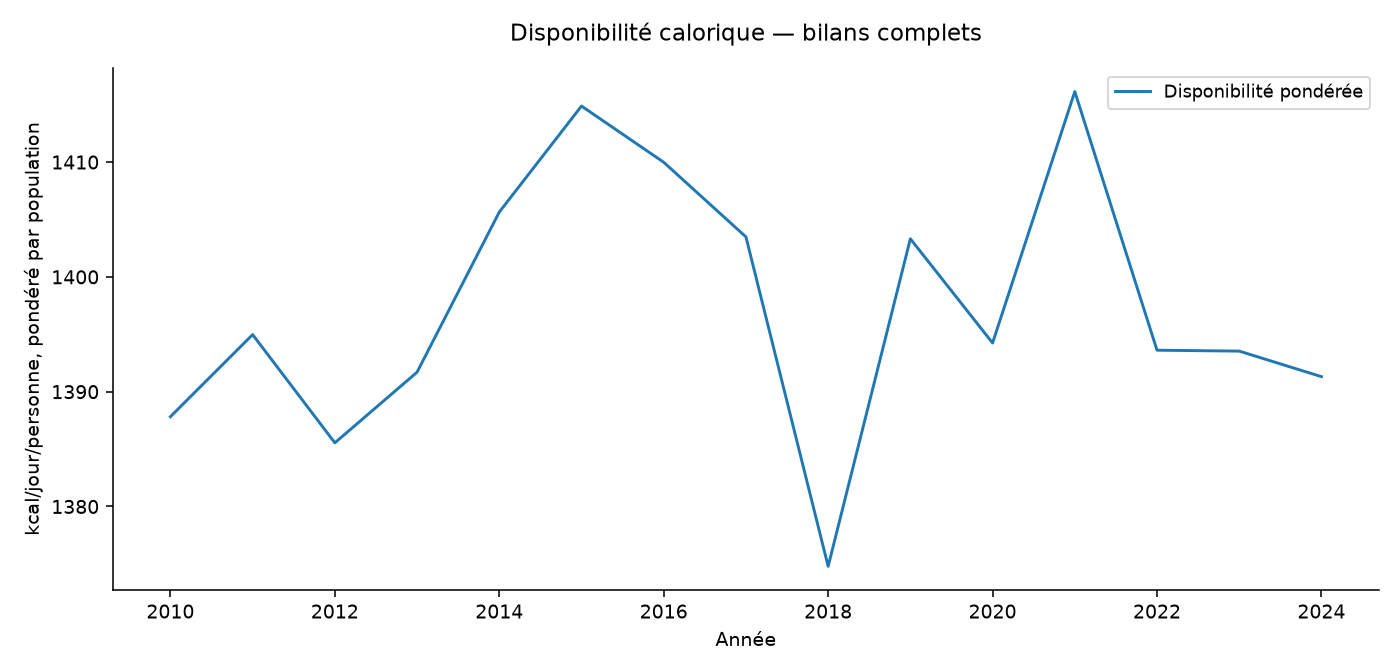

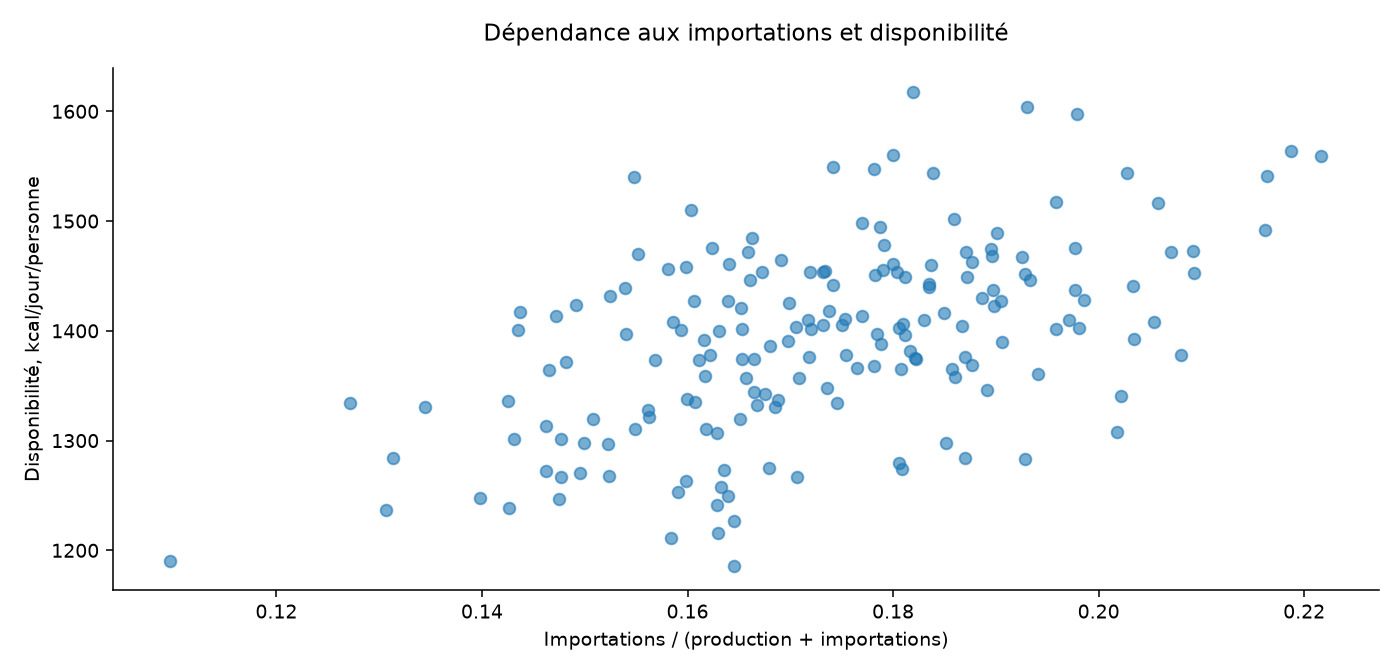

In [22]:
finish('NutriTerra — disponibilité et pertes alimentaires', 'Prioriser des explorations de sécurité alimentaire sans confondre disponibilité et consommation.', {'lignes_valides': len(v), 'pays': nc, 'pays_annees_incomplets': int((~c.bilan_complet).sum()), 'importations_imputees': int(v.importations_imputees.sum()), 'kcal_ponderees_2024': y.kcal_ponderees.iloc[-1], 'gain_median_scenario_2024': latest.gain_scenario.median()}, tables, [f'{len(v):,} bilans contrôlés ; {int(v.importations_imputees.sum())} importations interpolées avec traçabilité.', f'Gain médian théorique, réduction des pertes de 25 % : {latest.gain_scenario.median():.1f} kcal/jour/personne.'], ['Croiser faible disponibilité et dépendance aux importations.', 'Tester les références caloriques et hypothèses de pertes avant restitution.'], ['Aucune donnée réelle organisme réel ; territoires fictifs. Bilans pays-années incomplets exclus des comparaisons agrégées.', 'Disponibilité nationale différente de consommation individuelle ; aucune estimation de sous-nutrition.', 'Interpolation rétrospective descriptive, impropre à une prévision sans adaptation.'])

In [23]:
import pandas as pd, numpy as np

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [24]:
r = Restitution()

In [25]:
m = r.m

In [26]:
n = r.number

In [27]:
p = r.pct

In [28]:
e = r.money

In [29]:
v = r.read('data/processed/bilans_enrichis.csv')

In [30]:
c = r.read('analysis/pays_annees.csv')

In [31]:
y = r.read('analysis/tendance_ponderee.csv')

In [32]:
sc = r.read('analysis/sensibilite.csv')

In [33]:
latest = c[(c.annee == 2024) & c.bilan_complet].copy()

In [34]:
lv = v[v.annee == 2024].copy()

In [35]:
lv['kcal_population'] = lv.kcal_jour_personne * lv.population

In [36]:
pop = latest.population.sum()

In [37]:
by = lv.groupby('categorie').agg(kcal_population=('kcal_population', 'sum'), production_t=('production_t', 'sum'), pertes_t=('pertes_t', 'sum')).reset_index()

In [38]:
by['kcal_jour_personne_ponderees'] = by.kcal_population / pop

In [39]:
by['part_energie'] = by.kcal_population / by.kcal_population.sum()

In [40]:
by['pertes_sur_production'] = by.pertes_t / by.production_t

In [41]:
rank = latest.assign(priorite=lambda d: d.kcal_jour_personne.rank(pct=True, ascending=False) * 0.6 + d.dependance_imports.rank(pct=True) * 0.4).sort_values('priorite', ascending=False).head(12)[['pays_id', 'kcal_jour_personne', 'dependance_imports', 'gain_scenario', 'priorite']]

In [42]:
coverage = c.groupby('annee').apply(lambda d: pd.Series({'pays_complets': d.bilan_complet.sum(), 'population_totale': d.population.sum(), 'population_bilans_complets': d.loc[d.bilan_complet, 'population'].sum()})).reset_index()

In [43]:
coverage['couverture_population'] = coverage.population_bilans_complets / coverage.population_totale

In [44]:
simple = latest.kcal_jour_personne.mean()

In [45]:
weighted = np.average(latest.kcal_jour_personne, weights=latest.population)

In [46]:
qtiles = latest[['kcal_jour_personne', 'gain_scenario', 'dependance_imports']].quantile([0.1, 0.25, 0.5, 0.75, 0.9]).reset_index(names='quantile')

In [47]:
r.resume = [f"NutriTerra audite {n(m['lignes_valides'], 0)} bilans produit-territoire-année et 2 700 couples territoire-année attendus. {m['pays_annees_incomplets']} bilans territoriaux sont incomplets et exclus des comparaisons complètes.", f'En 2024, la disponibilité théorique pondérée vaut {n(weighted, 1)} kcal/jour/personne, contre {n(simple, 1)} pour une moyenne simple des territoires. Cette mesure n’est pas une consommation individuelle.', f"{m['importations_imputees']} importations sont interpolées et marquées. Les gains médians d’une réduction des pertes de 25 % sont de {n(latest.gain_scenario.median(), 1)} kcal/jour/personne.", f'Douze scénarios montrent une plage de {int(sc.pays_sous_reference.min())} à {int(sc.pays_sous_reference.max())} territoires sous les références illustratives ; ces décomptes ne mesurent pas la sous-nutrition.']

In [48]:
r.section('4. Reconstruire un bilan avec des unités compatibles', ['La disponibilité en tonnes est définie par production + importations − exportations + variation de stock − pertes − alimentation animale − autres usages. Le signe de variation de stock est une convention de la simulation : positif signifie apport au bilan disponible. Il doit être vérifié avant de réutiliser la formule sur une source réelle.', 'Chaque flux est en tonnes annuelles. Multiplier la disponibilité par 1 000 convertit en kilogrammes ; multiplier par kcal/kg donne des kcal annuelles. Diviser par population et par 365,25 donne une disponibilité moyenne journalière par personne. Une erreur de conversion tonnes/kg aurait un facteur 1 000, bien plus important que les variations étudiées.', f"Les {n(m['lignes_valides'], 0)} lignes conservées se joignent aux produits et populations avec une relation plusieurs-vers-un. Les facteurs énergétiques proviennent du référentiel fictif, pas d’une table nutritionnelle officielle. La conversion ne représente ni absorption, ni consommation effective.", 'Les lignes produit s’additionnent pour construire le bilan d’un territoire-année. Les populations sont répétées sur chaque produit et ne doivent donc jamais être additionnées sur cette table : le dénominateur territorial est pris une seule fois.'], [('Contributions des catégories en 2024', by[['categorie', 'kcal_jour_personne_ponderees', 'part_energie', 'pertes_sur_production']])])

## 4. Reconstruire un bilan avec des unités compatibles

La disponibilité en tonnes est définie par production + importations − exportations + variation de stock − pertes − alimentation animale − autres usages. Le signe de variation de stock est une convention de la simulation : positif signifie apport au bilan disponible. Il doit être vérifié avant de réutiliser la formule sur une source réelle.

Chaque flux est en tonnes annuelles. Multiplier la disponibilité par 1 000 convertit en kilogrammes ; multiplier par kcal/kg donne des kcal annuelles. Diviser par population et par 365,25 donne une disponibilité moyenne journalière par personne. Une erreur de conversion tonnes/kg aurait un facteur 1 000, bien plus important que les variations étudiées.

Les 48 575 lignes conservées se joignent aux produits et populations avec une relation plusieurs-vers-un. Les facteurs énergétiques proviennent du référentiel fictif, pas d’une table nutritionnelle officielle. La conversion ne représente ni absorption, ni consommation effective.

Les lignes produit s’additionnent pour construire le bilan d’un territoire-année. Les populations sont répétées sur chaque produit et ne doivent donc jamais être additionnées sur cette table : le dénominateur territorial est pris une seule fois.

### Contributions des catégories en 2024

      categorie  kcal_jour_personne_ponderees  part_energie  \
0        Autres                    160.991849      0.115712   
1      Cereales                    212.317167      0.152602   
2        Fruits                    285.805900      0.205422   
3       Legumes                    258.106507      0.185513   
4  Legumineuses                    180.705926      0.129882   
5       Viandes                    293.382500      0.210868   

   pertes_sur_production  
0               0.070748  
1               0.070000  
2               0.070273  
3               0.070043  
4               0.069671  
5               0.072589  

In [49]:
r.section('5. Couverture, interpolation et qualité des comparaisons', [f"La grille attendue comporte 180 × 15 = 2 700 couples territoire-année. {m['pays_annees_incomplets']} n’ont pas les 18 produits valides nécessaires. La grille complète est conservée, y compris lorsqu’aucun produit valide ne reste ; cela évite de faire disparaître silencieusement un territoire.", f"Les {m['importations_imputees']} valeurs d’importations manquantes sont interpolées au sein de la série territoire-produit, avec prolongement aux bords. Cette convention utilise potentiellement le futur et ne convient donc pas telle quelle à une prévision. Le drapeau importations_imputees permet de distinguer mesure simulée et remplacement.", 'L’exclusion de bilans incomplets n’est pas neutre : si les territoires incomplets différaient systématiquement des autres, la moyenne complète serait biaisée. La couverture en population est publiée par année, et l’année de référence est choisie avec un périmètre complet pour les comparaisons finales.', 'Le contrôle ne déduit pas une valeur calorique nulle lorsqu’un produit ou une importation manque. Le zéro est une information quantitative ; le manque est une absence d’information. Les confondre produirait artificiellement des territoires très déficitaires.'], [('Couverture temporelle', coverage[['annee', 'pays_complets', 'couverture_population']])])

## 5. Couverture, interpolation et qualité des comparaisons

La grille attendue comporte 180 × 15 = 2 700 couples territoire-année. 2 n’ont pas les 18 produits valides nécessaires. La grille complète est conservée, y compris lorsqu’aucun produit valide ne reste ; cela évite de faire disparaître silencieusement un territoire.

Les 380 valeurs d’importations manquantes sont interpolées au sein de la série territoire-produit, avec prolongement aux bords. Cette convention utilise potentiellement le futur et ne convient donc pas telle quelle à une prévision. Le drapeau importations_imputees permet de distinguer mesure simulée et remplacement.

L’exclusion de bilans incomplets n’est pas neutre : si les territoires incomplets différaient systématiquement des autres, la moyenne complète serait biaisée. La couverture en population est publiée par année, et l’année de référence est choisie avec un périmètre complet pour les comparaisons finales.

Le contrôle ne déduit pas une valeur calorique nulle lorsqu’un produit ou une importation manque. Le zéro est une information quantitative ; le manque est une absence d’information. Les confondre produirait artificiellement des territoires très déficitaires.

### Couverture temporelle

    annee  pays_complets  couverture_population
0    2010          179.0               0.990310
1    2011          179.0               0.990259
2    2012          180.0               1.000000
3    2013          180.0               1.000000
4    2014          180.0               1.000000
5    2015          180.0               1.000000
6    2016          180.0               1.000000
7    2017          180.0               1.000000
8    2018          180.0               1.000000
9    2019          180.0               1.000000
10   2020          180.0               1.000000
11   2021          180.0               1.000000
12   2022          180.0               1.000000
13   2023          180.0               1.000000
14   2024          180.0               1.000000

In [50]:
r.section('6. Moyenne pondérée et distribution des disponibilités', [f'La moyenne simple des territoires vaut {n(simple, 1)} kcal/jour/personne et la moyenne pondérée {n(weighted, 1)}. L’écart de {n(weighted - simple, 1)} résulte des poids de population, pas d’un changement du numérateur individuel. Un petit territoire ne doit pas peser autant qu’un territoire beaucoup plus peuplé lorsqu’on décrit l’ensemble des personnes.', f'La médiane territoriale est {n(latest.kcal_jour_personne.median(), 1)}, avec un intervalle interquartile de {n(latest.kcal_jour_personne.quantile(0.25), 1)} à {n(latest.kcal_jour_personne.quantile(0.75), 1)}. Les quantiles sont non pondérés et décrivent les territoires ; ils ne sont pas les quantiles de consommation des individus.', f'Entre la première et la dernière année de la série pondérée, la variation est {p(y.kcal_ponderees.iloc[-1] / y.kcal_ponderees.iloc[0] - 1, 2)}. Cette évolution dépend de flux et populations programmés ; aucune politique publique ne peut lui être attribuée.', 'La dépendance aux importations est importations / (production + importations). Elle est ici un indicateur de sourcing et non un bilan commercial complet : les exportations, le coût et la diversité des partenaires ne figurent pas au dénominateur.'], [('Distribution en 2024', qtiles)])

## 6. Moyenne pondérée et distribution des disponibilités

La moyenne simple des territoires vaut 1 392,9 kcal/jour/personne et la moyenne pondérée 1 391,3. L’écart de -1,6 résulte des poids de population, pas d’un changement du numérateur individuel. Un petit territoire ne doit pas peser autant qu’un territoire beaucoup plus peuplé lorsqu’on décrit l’ensemble des personnes.

La médiane territoriale est 1 401,2, avec un intervalle interquartile de 1 335,0 à 1 452,5. Les quantiles sont non pondérés et décrivent les territoires ; ils ne sont pas les quantiles de consommation des individus.

Entre la première et la dernière année de la série pondérée, la variation est 0,25 %. Cette évolution dépend de flux et populations programmés ; aucune politique publique ne peut lui être attribuée.

La dépendance aux importations est importations / (production + importations). Elle est ici un indicateur de sourcing et non un bilan commercial complet : les exportations, le coût et la diversité des partenaires ne figurent pas au dénominateur.

### Distribution en 2024

   quantile  kcal_jour_personne  gain_scenario  dependance_imports
0      0.10         1272.381803      22.630124            0.148124
1      0.25         1335.047920      24.638216            0.160982
2      0.50         1401.215955      27.446092            0.173175
3      0.75         1452.533068      29.408714            0.186199
4      0.90         1492.466031      31.778433            0.197724

In [51]:
r.section('7. Scénarios de pertes et références illustratives', [f'Une réduction de 25 % des pertes ajouterait, à autres flux inchangés, un gain médian de {n(latest.gain_scenario.median(), 1)} kcal/jour/personne. Les gains varient de {n(latest.gain_scenario.min(), 1)} à {n(latest.gain_scenario.max(), 1)} selon le territoire. Il s’agit d’un potentiel comptable, pas d’une garantie de récupération ou de distribution.', 'Les douze scénarios combinent quatre réductions de pertes (0, 10, 25, 50 %) et trois références illustratives (1 800, 2 100, 2 400 kcal). Ils évaluent la sensibilité d’un décompte conventionnel. Les références ne constituent pas des besoins médicaux individuels, qui varient et ne sont pas modélisés.', f'Le nombre de territoires sous référence s’étend de {int(sc.pays_sous_reference.min())} à {int(sc.pays_sous_reference.max())}. Si certains scénarios donnent le même nombre, le seuil ne discrimine pas les territoires dans cette simulation. Cela n’invalide pas le calcul, mais limite son intérêt pour une priorisation.', 'Le scénario conserve production, échanges et autres usages. Une action réelle pourrait déplacer ces flux ou augmenter les coûts ; la simplicité du scénario doit apparaître dans la restitution, et une analyse de faisabilité doit précéder toute intervention.'], [('Sensibilité des décomptes', sc)])

## 7. Scénarios de pertes et références illustratives

Une réduction de 25 % des pertes ajouterait, à autres flux inchangés, un gain médian de 27,4 kcal/jour/personne. Les gains varient de 19,8 à 36,4 selon le territoire. Il s’agit d’un potentiel comptable, pas d’une garantie de récupération ou de distribution.

Les douze scénarios combinent quatre réductions de pertes (0, 10, 25, 50 %) et trois références illustratives (1 800, 2 100, 2 400 kcal). Ils évaluent la sensibilité d’un décompte conventionnel. Les références ne constituent pas des besoins médicaux individuels, qui varient et ne sont pas modélisés.

Le nombre de territoires sous référence s’étend de 180 à 180. Si certains scénarios donnent le même nombre, le seuil ne discrimine pas les territoires dans cette simulation. Cela n’invalide pas le calcul, mais limite son intérêt pour une priorisation.

Le scénario conserve production, échanges et autres usages. Une action réelle pourrait déplacer ces flux ou augmenter les coûts ; la simplicité du scénario doit apparaître dans la restitution, et une analyse de faisabilité doit précéder toute intervention.

### Sensibilité des décomptes

    reference_theorique_kcal  reduction_pertes  pays_sous_reference
0                       1800              0.00                  180
1                       1800              0.10                  180
2                       1800              0.25                  180
3                       1800              0.50                  180
4                       2100              0.00                  180
5                       2100              0.10                  180
6                       2100              0.25                  180
7                       2100              0.50                  180
8                       2400              0.00                  180
9                       2400              0.10                  180
10                      2400              0.25                  180
11                      2400              0.50                  180

In [52]:
r.section('8. Prioriser une exploration plutôt qu’un diagnostic sanitaire', ['Le classement exploratoire combine le rang de faible disponibilité à 60 % et le rang de dépendance aux importations à 40 %. Ces poids expriment une préférence de travail, pas une estimation de risque. Le score utilise des rangs pour éviter de sommer directement des kcal et des proportions.', 'Les douze premières lignes constituent un panel d’investigation. Il faudrait ensuite vérifier prix alimentaires, inégalités d’accès, infrastructures, pertes par étape et qualité des données. Une disponibilité nationale moyenne peut coexister avec des difficultés d’accès économique ou de distribution.', 'Aucun indicateur présenté ne mesure la prévalence de sous-nutrition. Passer du bilan agrégé à un résultat sanitaire demanderait des données individuelles ou des modèles appropriés, des définitions validées et une évaluation spécialisée.', 'La décision proposée est donc de documenter les territoires sélectionnés et de tester les hypothèses de pertes, plutôt que de leur attribuer automatiquement un programme fondé sur un seuil calorique unique.'], [('Panel de territoires fictifs à étudier', rank)])

## 8. Prioriser une exploration plutôt qu’un diagnostic sanitaire

Le classement exploratoire combine le rang de faible disponibilité à 60 % et le rang de dépendance aux importations à 40 %. Ces poids expriment une préférence de travail, pas une estimation de risque. Le score utilise des rangs pour éviter de sommer directement des kcal et des proportions.

Les douze premières lignes constituent un panel d’investigation. Il faudrait ensuite vérifier prix alimentaires, inégalités d’accès, infrastructures, pertes par étape et qualité des données. Une disponibilité nationale moyenne peut coexister avec des difficultés d’accès économique ou de distribution.

Aucun indicateur présenté ne mesure la prévalence de sous-nutrition. Passer du bilan agrégé à un résultat sanitaire demanderait des données individuelles ou des modèles appropriés, des définitions validées et une évaluation spécialisée.

La décision proposée est donc de documenter les territoires sélectionnés et de tester les hypothèses de pertes, plutôt que de leur attribuer automatiquement un programme fondé sur un seuil calorique unique.

### Panel de territoires fictifs à étudier

      pays_id  kcal_jour_personne  dependance_imports  gain_scenario  priorite
569        37         1283.668932            0.192863      26.558663  0.863333
929        61         1307.727455            0.201786      26.288806  0.862222
2444      162         1283.703150            0.187005      24.227582  0.824444
314        20         1341.020923            0.202201      31.525130  0.807778
1379       91         1297.597153            0.185163      31.729954  0.803333
659        43         1273.780633            0.180870      23.066541  0.795556
1844      122         1279.975748            0.180564      24.239874  0.782222
1289       85         1361.003841            0.194139      23.306013  0.755556
1154       76         1345.931840            0.189173      22.407155  0.746667
959        63         1266.619767            0.170613      26.358564  0.740000
2579      171         1185.399529            0.164549      32.110945  0.737778
899        59         1377.992379            0.20803

In [53]:
r.actions = [('P1', str(m['pays_annees_incomplets']) + ' bilans incomplets', 'Réconcilier la grille attendue et publier la couverture', '2 700 couples attendus et 18 produits par bilan complet'), ('P1', str(m['importations_imputees']) + ' valeurs interpolées', 'Tester les résultats avec et sans imputations dans une étude réelle', 'Impact de périmètre et hypothèses de bord documentés'), ('P2', 'Gain médian de ' + n(latest.gain_scenario.median(), 1) + ' kcal théoriques', 'Étudier la faisabilité d’une baisse des pertes', 'Flux récupérables, coûts et distribution vérifiés'), ('P2', 'Scoring conventionnel 60/40', 'Utiliser le classement comme panel d’exploration', 'Pas de conclusion sanitaire ou d’allocation automatique')]

In [54]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

NutriTerra audite 48 575 bilans produit-territoire-année et 2 700 couples territoire-année attendus. 2 bilans territoriaux sont incomplets et exclus des comparaisons complètes.

En 2024, la disponibilité théorique pondérée vaut 1 391,3 kcal/jour/personne, contre 1 392,9 pour une moyenne simple des territoires. Cette mesure n’est pas une consommation individuelle.

380 importations sont interpolées et marquées. Les gains médians d’une réduction des pertes de 25 % sont de 27,4 kcal/jour/personne.

Douze scénarios montrent une plage de 180 à 180 territoires sous les références illustratives ; ces décomptes ne mesurent pas la sous-nutrition.

    0                                    1  \
0  P1                  2 bilans incomplets   
1  P1              380 valeurs interpolées   
2  P2  Gain médian de 27,4 kcal théoriques   
3  P2          Scoring conventionnel 60/40   

                                                   2  \
0  Réconcilier la grille attendue et publier la c...   
1  Tester les résultats avec et sans imputations ...   
2     Étudier la faisabilité d’une baisse des pertes   
3   Utiliser le classement comme panel d’exploration   

                                                   3  
0  2 700 couples attendus et 18 produits par bila...  
1  Impact de périmètre et hypothèses de bord docu...  
2  Flux récupérables, coûts et distribution vérifiés  
3  Pas de conclusion sanitaire ou d’allocation au...  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [55]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
